In [10]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

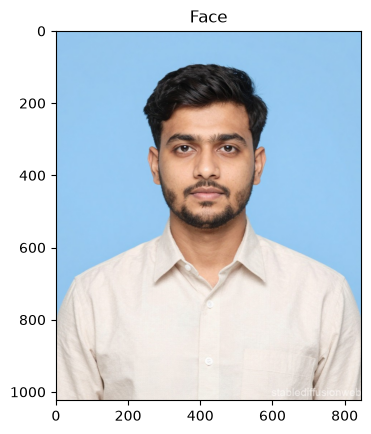

In [47]:
# Load the Face Image
faceImage = cv2.imread('08.jpg')
plt.imshow(faceImage[:, :, ::-1])
plt.title("Face")

In [48]:
faceImage.shape

(1024, 846, 3)

In [49]:
#resized_faceImage.shape
faceImage.shape

(1024, 846, 3)

Text(0.5, 1.0, 'glassPNG')

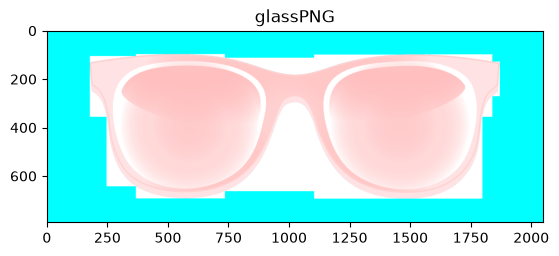

In [62]:
# Load the Sunglass image with Alpha channel
glassPNG = cv2.imread('sunglass.png', -1)

plt.imshow(glassPNG[:, :, ::-1])
plt.title("glassPNG")

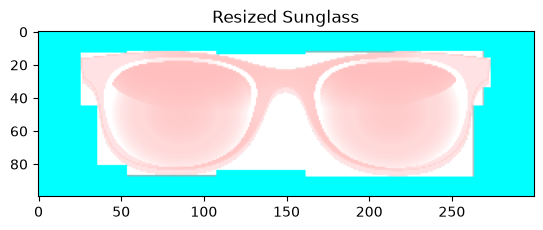

In [63]:
# Resize the image to fit over the eye region
glass = cv2.resize(glassPNG, (300, 100))

plt.imshow(glass[:, :, ::-1])
plt.title("Resized Sunglass")
plt.show()

In [64]:
# Separate the Color and alpha channels
glassBGR = glass[:, :, :3]
glassAlpha = glass[:, :, 3]

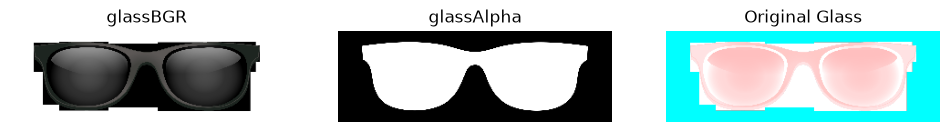

In [65]:
# Display the images for clarity

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(glassBGR[:, :, ::-1])
plt.title("glassBGR")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(glassAlpha, cmap="gray")
plt.title("glassAlpha")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(glass[:, :, ::-1])
plt.title("Original Glass")
plt.axis("off")

plt.show()

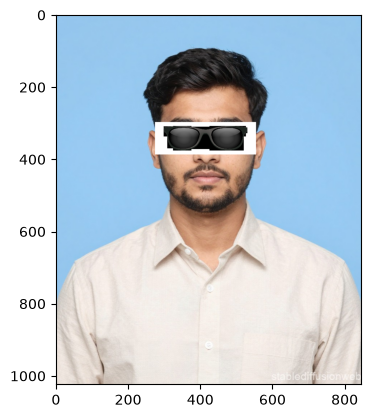

In [77]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Replace the eye region with the sunglass image
faceWithGlassesNaive[297:387, 275:555] = glassBGR

plt.imshow(faceWithGlassesNaive[:, :, ::-1])

Text(0.5, 1.0, 'Augmented Eye and Sunglass')

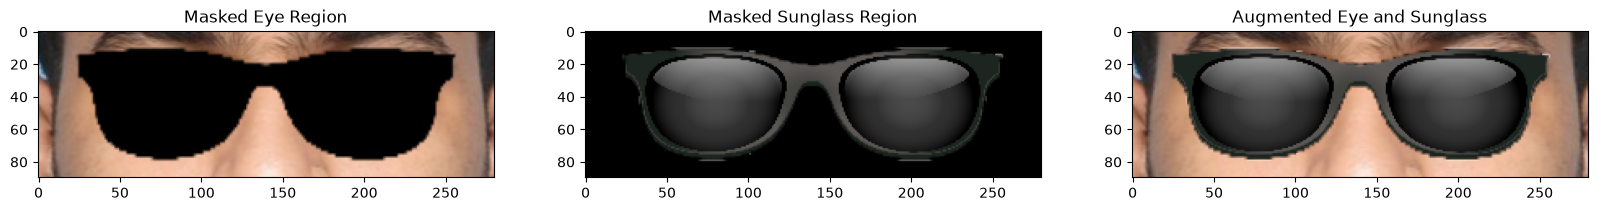

In [81]:
# Resize the mask
glassMask1 = cv2.resize(glassMask1, (280, 90))

# Make the dimensions of the mask same as the input image
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Make the values [0,1]
glassMask = glassMask.astype(np.float32) / 255

# Convert images to float
eyeROI = eyeROI.astype(np.float32)
glassBGR = glassBGR.astype(np.float32)

# Use the mask to create the masked eye region
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

# Use the mask to create the masked sunglass region
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine the Sunglass and Eye Region
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Convert back to uint8
eyeRoiFinal = eyeRoiFinal.astype(np.uint8)

# Display
plt.figure(figsize=[20,20])
plt.subplot(131); plt.imshow(maskedEye.astype(np.uint8)[...,::-1]); plt.title("Masked Eye Region")
plt.subplot(132); plt.imshow(maskedGlass.astype(np.uint8)[...,::-1]); plt.title("Masked Sunglass Region")
plt.subplot(133); plt.imshow(eyeRoiFinal[...,::-1]); plt.title("Augmented Eye and Sunglass")

Text(0.5, 1.0, 'With Sunglasses')

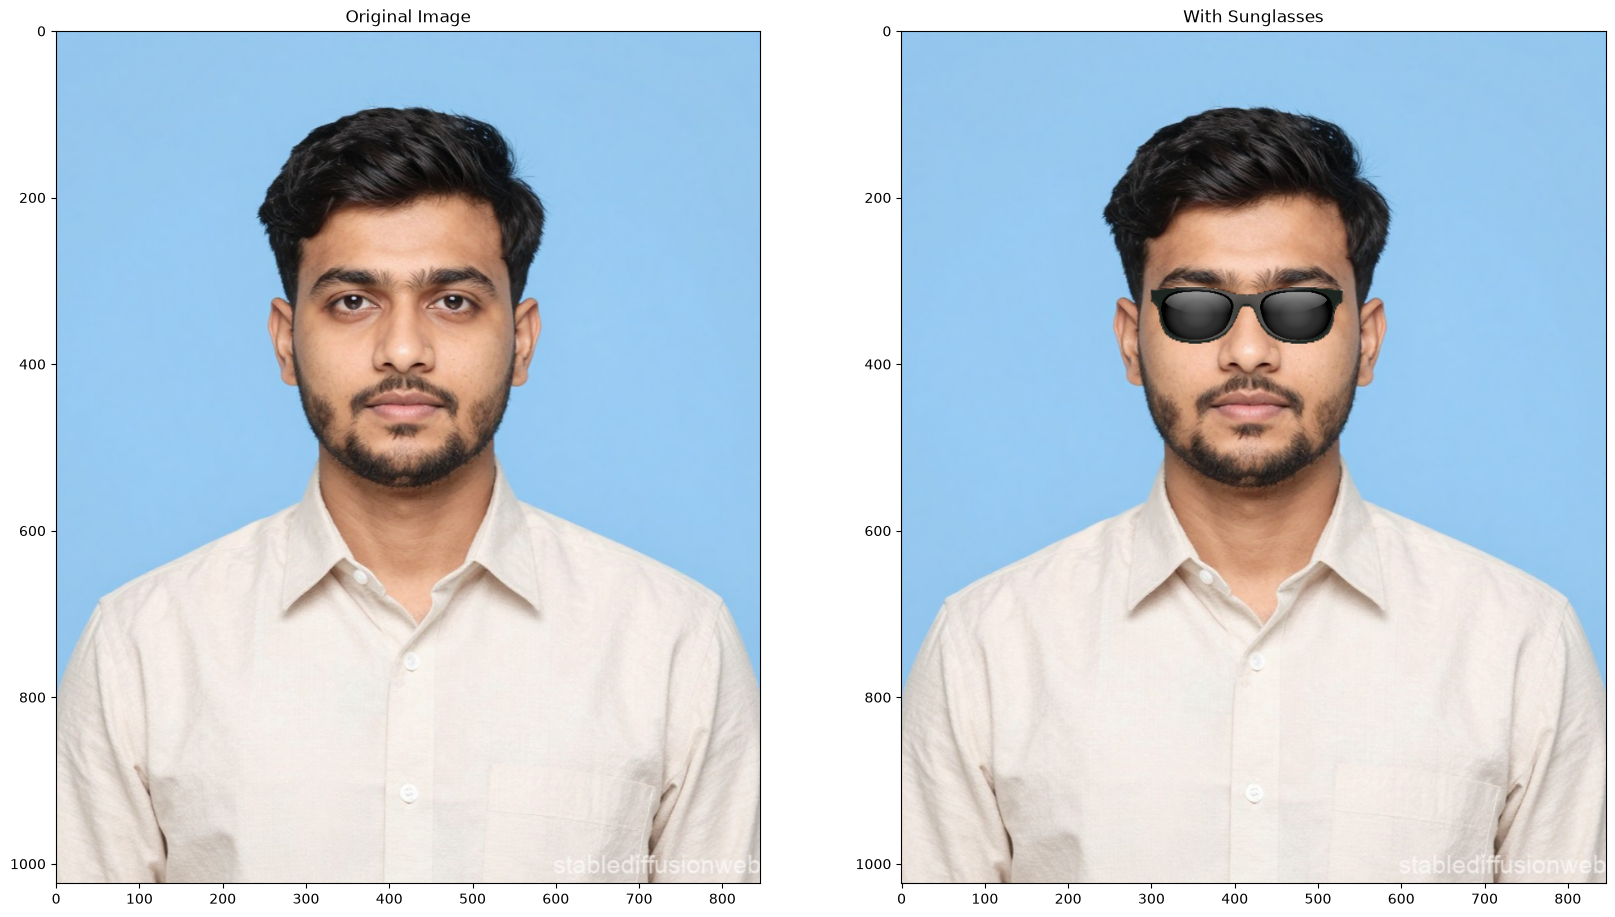

In [82]:
# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic[297:387,275:555] = eyeRoiFinal

# Display the final result
plt.figure(figsize=[20,20])
plt.subplot(121); plt.imshow(faceImage[:,:,::-1]); plt.title("Original Image")
plt.subplot(122); plt.imshow(faceWithGlassesArithmetic[:,:,::-1]); plt.title("With Sunglasses")